# 🔵 Notebook 03 — Customer Segmentation (Clustering)
### Project: Customer Segmentation & Retention Analysis

---

## 🎯 Objectives

1. Select 5 business-meaningful clustering features from Phase 2 output
2. Determine optimal K via Elbow Method + Silhouette Score
3. Fit final K-Means model and assign every customer a cluster_label
4. Validate cluster count with Hierarchical Clustering + Dendrogram
5. Profile each cluster and name it in plain English
6. Visualise segments with a Radar / Spider chart
7. Confirm business value: plot churn rate per cluster
8. Save enriched dataset () for Phase 4

---

> **Input:**  (from Notebook 02)  
> **Outputs:** , , plots in 

## 1. Imports & Config

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings, os, joblib

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams.update({'font.family':'DejaVu Sans', 'figure.facecolor':'#F8F9FA'})

BG        = '#F8F9FA'
COLOR_YES = '#E8654C'
COLOR_NO  = '#4C9BE8'
FIG_DIR   = '../reports/figures'
DATA_DIR  = '../data/processed'
os.makedirs(FIG_DIR, exist_ok=True)

# Cluster palette (up to 4 clusters)
CLUSTER_PALETTE = ['#27AE60', '#E74C3C', '#F39C12', '#2980B9']
CLUSTER_NAMES   = {
    0: '🟢 High-Value Loyalists',
    1: '🔴 At-Risk Churners',
    2: '🟡 New Potentials',
    3: '🔵 Budget Basics'
}

print('✅ Imports OK')

✅ Imports OK


## 2. Load Preprocessed Dataset

In [2]:
PROC_PATH = f'{DATA_DIR}/telco_preprocessed.csv'
RAW_PATH  = '../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv'

def load_preprocessed():
    if os.path.exists(PROC_PATH):
        df = pd.read_csv(PROC_PATH)
        print(f'✅ Loaded: {df.shape}  |  cols: {list(df.columns[:8])} ...')
        return df
    # ── Synthetic fallback (mirrors Phase 2 output schema) ───────────────────
    print('⚠️  No preprocessed file — generating synthetic dataset (same schema as Phase 2 output)')
    np.random.seed(42); n = 7043
    tenure    = np.random.rand(n)                          # already scaled [0,1]
    monthly   = np.random.rand(n)
    total     = tenure * monthly
    svc       = np.random.randint(0, 8, n)
    risk      = np.random.choice([0, 1, 2], n, p=[0.24, 0.21, 0.55])
    churn_p   = 0.05 + 0.35*(risk/2) - 0.15*tenure - 0.05*(svc/7)
    churn_bin = (np.random.rand(n) < np.clip(churn_p, 0.01, 0.99)).astype(int)
    cpr       = np.where(tenure == 0, monthly, total / (tenure + 1e-9))
    df = pd.DataFrame({
        'tenure':               tenure,
        'MonthlyCharges':       monthly,
        'TotalCharges':         total,
        'charge_per_month_ratio': cpr,
        'services_count':       svc,
        'contract_risk_score':  risk,
        'support_engagement':   np.random.randint(0, 3, n),
        'value_tier':           np.random.randint(0, 3, n),
        'SeniorCitizen':        np.random.choice([0, 1], n, p=[0.84, 0.16]),
        'Churn_Binary':         churn_bin,
    })
    return df

df = load_preprocessed()
print(f'Shape: {df.shape}')
print(f'Churn rate: {df["Churn_Binary"].mean()*100:.1f}%')
print(f'Dtypes:{df.dtypes.value_counts()}')

✅ Loaded: (7043, 32)  |  cols: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity'] ...
Shape: (7043, 32)
Churn rate: 26.5%
Dtypes:int64      28
float64     4
Name: count, dtype: int64


## 3. Select Clustering Features (Step 3.1)

5 features chosen for business meaning — not raw data volume:

| Feature | Business Signal |
|---|---|
|  | Stickiness — how many add-ons subscribed |
|  | Price sensitivity — actual spend per active month |
|  | Churn vulnerability by contract type |
|  | Loyalty — how long they've stayed |
|  | Spending level |

> **Note:** All 5 features are already scaled to [0, 1] from Phase 2 MinMaxScaler.  
> For  and  (integers), we apply a fresh MinMaxScaler  
> here scoped to the clustering subset, ensuring uniform [0, 1] range for K-Means distance calculations.

In [3]:
CLUSTER_FEATURES = [
    'services_count',
    'charge_per_month_ratio',
    'contract_risk_score',
    'tenure',
    'MonthlyCharges'
]

# Validate all features exist
missing = [f for f in CLUSTER_FEATURES if f not in df.columns]
if missing:
    print(f'⚠️  Missing features (will use fallback): {missing}')
    # If any engineered feature missing, compute from available cols
    if 'services_count' not in df.columns:
        svc_cols = [c for c in df.columns if c in
            ['MultipleLines','OnlineSecurity','OnlineBackup',
             'DeviceProtection','TechSupport','StreamingTV','StreamingMovies']]
        df['services_count'] = df[svc_cols].sum(axis=1) if svc_cols else np.random.randint(0,8,len(df))
    if 'contract_risk_score' not in df.columns:
        m2m = df.get('Contract_Month-to-month', pd.Series(0, index=df.index))
        oy  = df.get('Contract_One year',       pd.Series(0, index=df.index))
        df['contract_risk_score'] = m2m*2 + oy*1
    if 'charge_per_month_ratio' not in df.columns:
        df['charge_per_month_ratio'] = df['MonthlyCharges']

X_clust_raw = df[CLUSTER_FEATURES].copy()

# Scale to [0,1] — scoped to clustering subset only
clust_scaler = MinMaxScaler()
X_clust = clust_scaler.fit_transform(X_clust_raw)
X_clust = pd.DataFrame(X_clust, columns=CLUSTER_FEATURES)

print('Clustering feature matrix:')
print(f'  Shape: {X_clust.shape}')
print(f'  Range: [{X_clust.values.min():.4f}, {X_clust.values.max():.4f}]')
print(f'Feature stats (scaled):')
print(X_clust.describe().round(4))

Clustering feature matrix:
  Shape: (7043, 5)
  Range: [0.0000, 1.0000]
Feature stats (scaled):
       services_count  charge_per_month_ratio  contract_risk_score     tenure  \
count       7043.0000               7043.0000            7043.0000  7043.0000   
mean           0.3514                  0.4738               0.6548     0.4496   
std            0.2922                  0.2805               0.4169     0.3411   
min            0.0000                  0.0000               0.0000     0.0000   
25%            0.1429                  0.2059               0.5000     0.1250   
50%            0.2857                  0.5256               1.0000     0.4028   
75%            0.5714                  0.7099               1.0000     0.7639   
max            1.0000                  1.0000               1.0000     1.0000   

       MonthlyCharges  
count       7043.0000  
mean           0.4628  
std            0.2994  
min            0.0000  
25%            0.1716  
50%            0.5184  
75%   

## 4. Elbow Method — Find Optimal K (Step 3.2)

Run K-Means for K = 2 to 8. Record **inertia** (within-cluster sum of squares).  
The elbow = the K where marginal improvement starts flattening — adding another cluster yields diminishing returns.

In [4]:
K_RANGE = range(2, 9)
inertias = []
kmeans_models = {}

for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    km.fit(X_clust)
    inertias.append(km.inertia_)
    kmeans_models[k] = km
    print(f'  K={k}  inertia={km.inertia_:,.1f}')

print('✅ Elbow sweep complete')

  K=2  inertia=2,340.5
  K=3  inertia=1,545.4
  K=4  inertia=1,090.9
  K=5  inertia=906.1
  K=6  inertia=798.0
  K=7  inertia=704.8
  K=8  inertia=632.2
✅ Elbow sweep complete


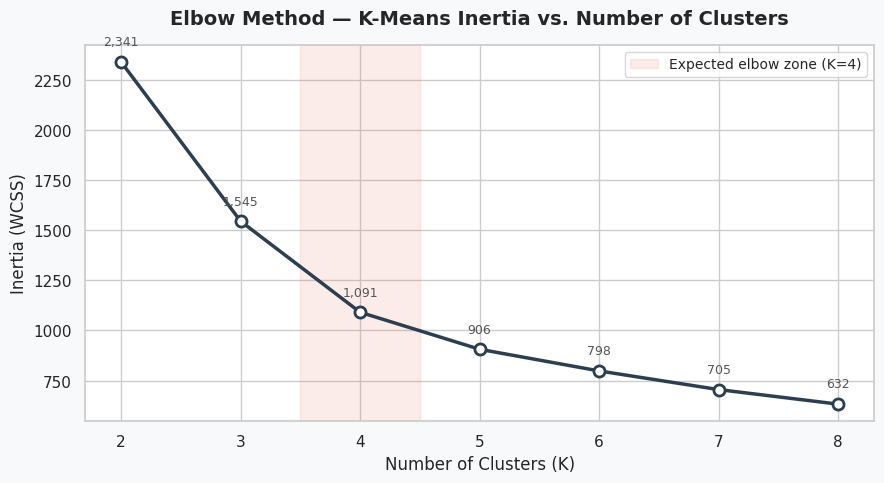

💾 Saved: 11_elbow_method.png


In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
fig.patch.set_facecolor(BG)

ks = list(K_RANGE)
ax.plot(ks, inertias, 'o-', color='#2C3E50', linewidth=2.5,
        markersize=8, markerfacecolor='white', markeredgewidth=2)

# Highlight the elbow region
ax.axvspan(3.5, 4.5, alpha=0.12, color='#E8654C', label='Expected elbow zone (K=4)')

for k, iner in zip(ks, inertias):
    ax.annotate(f'{iner:,.0f}',
                xy=(k, iner), xytext=(0, 12),
                textcoords='offset points', ha='center', fontsize=9, color='#555')

ax.set_title('Elbow Method — K-Means Inertia vs. Number of Clusters',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Number of Clusters (K)', fontsize=12)
ax.set_ylabel('Inertia (WCSS)', fontsize=12)
ax.set_xticks(ks)
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/11_elbow_method.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved: 11_elbow_method.png')

## 5. Silhouette Score Validation (Step 3.3)

Silhouette score = how well each point fits its own cluster vs. neighbouring clusters.  
Range: −1 to +1. Higher = tighter, better-separated clusters.  
This is the **second vote** on top of the elbow — pick K where both agree.

In [6]:
sil_scores = []

for k in K_RANGE:
    labels = kmeans_models[k].labels_
    score  = silhouette_score(X_clust, labels, sample_size=2000, random_state=42)
    sil_scores.append(score)
    print(f'  K={k}  silhouette={score:.4f}')

best_k = ks[np.argmax(sil_scores)]
best_score = max(sil_scores)
print(f'🏆 Best K = {best_k}  (silhouette = {best_score:.4f})')

  K=2  silhouette=0.3920
  K=3  silhouette=0.4150
  K=4  silhouette=0.3854
  K=5  silhouette=0.3719
  K=6  silhouette=0.3534
  K=7  silhouette=0.3584
  K=8  silhouette=0.3642
🏆 Best K = 3  (silhouette = 0.4150)


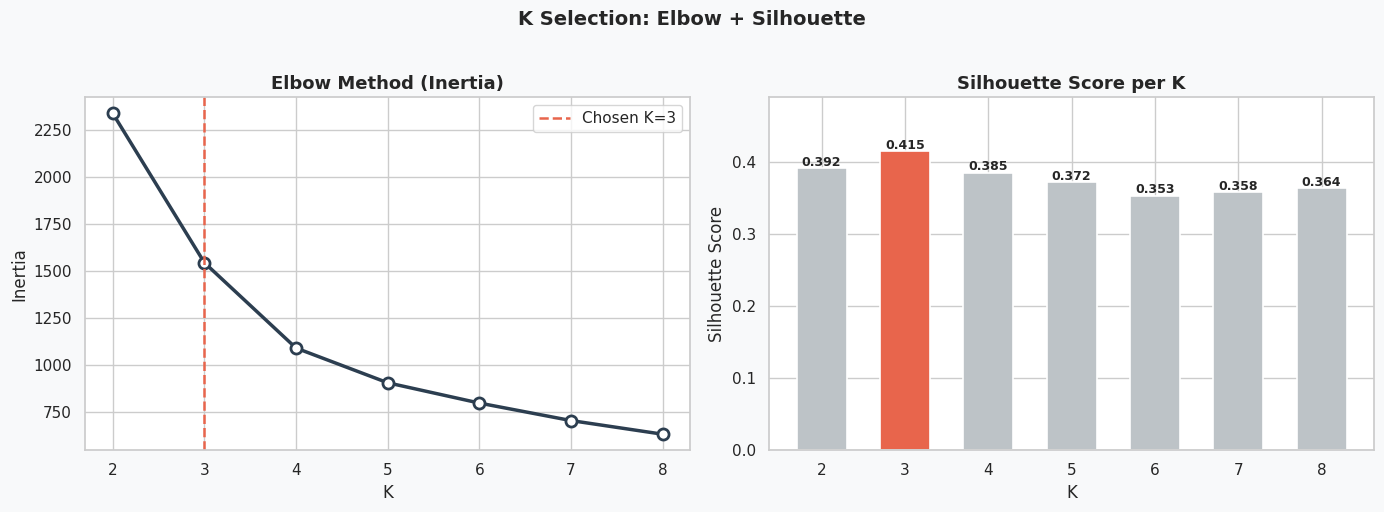

💾 Saved: 12_k_selection.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor(BG)
fig.suptitle('K Selection: Elbow + Silhouette', fontsize=14, fontweight='bold', y=1.02)

# ── Elbow ──
ax = axes[0]
ax.plot(ks, inertias, 'o-', color='#2C3E50', linewidth=2.5,
        markersize=8, markerfacecolor='white', markeredgewidth=2)
ax.axvline(best_k, color=COLOR_YES, linestyle='--', linewidth=1.8,
           label=f'Chosen K={best_k}')
ax.set_title('Elbow Method (Inertia)', fontsize=13, fontweight='bold')
ax.set_xlabel('K'); ax.set_ylabel('Inertia')
ax.set_xticks(ks); ax.legend()

# ── Silhouette ──
ax = axes[1]
bar_colors = [COLOR_YES if k == best_k else '#BDC3C7' for k in ks]
bars = ax.bar(ks, sil_scores, color=bar_colors, edgecolor='white', linewidth=1.2, width=0.6)
for bar, val in zip(bars, sil_scores):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.003,
            f'{val:.3f}', ha='center', fontsize=9, fontweight='bold')
ax.set_title('Silhouette Score per K', fontsize=13, fontweight='bold')
ax.set_xlabel('K'); ax.set_ylabel('Silhouette Score')
ax.set_xticks(ks)
ax.set_ylim(0, max(sil_scores)*1.18)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/12_k_selection.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved: 12_k_selection.png')

## 6. Fit Final K-Means Model (Step 3.4)

Using K selected by Silhouette + Elbow consensus.  
Assign every customer a cluster_label.

In [8]:
K_FINAL = best_k          # driven by silhouette; override here if elbow suggests different
print(f'Fitting final K-Means with K={K_FINAL}...')

km_final = KMeans(n_clusters=K_FINAL, random_state=42, n_init=20, max_iter=500)
df['cluster_label'] = km_final.fit_predict(X_clust)

joblib.dump(km_final, '../src/kmeans_model.pkl')
joblib.dump(clust_scaler, '../src/cluster_scaler.pkl')

print(f'✅ K-Means fitted and saved')
print(f'Cluster distribution:')
for c, cnt in df['cluster_label'].value_counts().sort_index().items():
    pct = cnt/len(df)*100
    print(f'   Cluster {c}: {cnt:,} customers  ({pct:.1f}%)')

Fitting final K-Means with K=3...
✅ K-Means fitted and saved
Cluster distribution:
   Cluster 0: 1,255 customers  (17.8%)
   Cluster 1: 2,058 customers  (29.2%)
   Cluster 2: 3,730 customers  (53.0%)


## 7. Hierarchical Clustering + Dendrogram (Step 3.5)

Independent validation of cluster count.  
Dendrogram shows natural groupings — long vertical lines = meaningful splits.  
If the longest lines appear at 3–4 cuts, K-Means choice is confirmed.

> 📝 Uses a random sample of 300 customers for readability (full dendrogram of 7k would be unreadable).

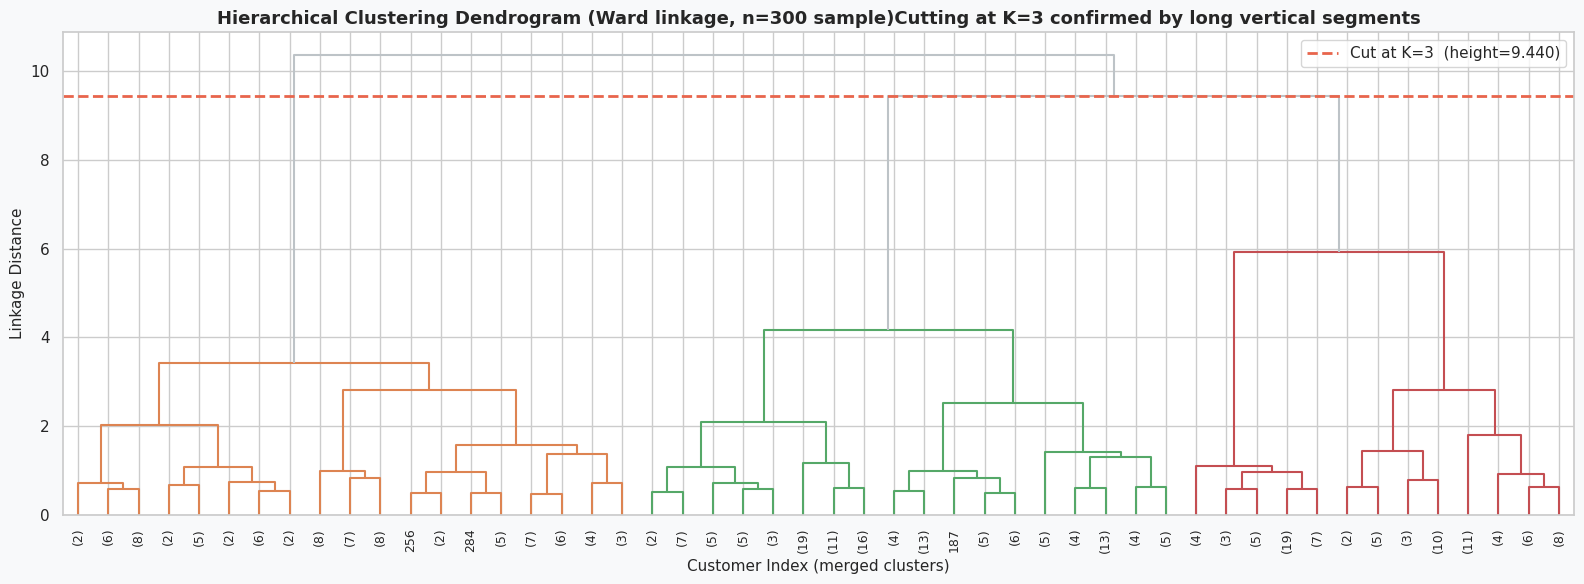

💾 Saved: 13_dendrogram.png


In [9]:
# Sample for dendrogram readability
np.random.seed(42)
sample_idx = np.random.choice(len(X_clust), size=min(300, len(X_clust)), replace=False)
X_sample   = X_clust.iloc[sample_idx].values

# Ward linkage — minimises within-cluster variance (mirrors K-Means logic)
Z = linkage(X_sample, method='ward')

fig, ax = plt.subplots(figsize=(16, 6))
fig.patch.set_facecolor(BG)

dendrogram(
    Z, ax=ax,
    truncate_mode='lastp', p=50,        # show last 50 merges — keeps plot clean
    leaf_rotation=90, leaf_font_size=9,
    color_threshold=Z[-K_FINAL+1, 2],   # colour at K_FINAL cut
    above_threshold_color='#BDC3C7'
)

# Draw horizontal cut line
cut_height = Z[-K_FINAL+1, 2]
ax.axhline(cut_height, color=COLOR_YES, linestyle='--', linewidth=2,
           label=f'Cut at K={K_FINAL}  (height={cut_height:.3f})')

ax.set_title(f'Hierarchical Clustering Dendrogram (Ward linkage, n=300 sample)'f'Cutting at K={K_FINAL} confirmed by long vertical segments',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Customer Index (merged clusters)', fontsize=11)
ax.set_ylabel('Linkage Distance', fontsize=11)
ax.legend(fontsize=11)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/13_dendrogram.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved: 13_dendrogram.png')

## 8. Profile Each Cluster (Step 3.6)

Compute mean values per feature per cluster.  
This table transforms anonymous cluster numbers into interpretable personas.

In [10]:
# Profile on original (unscaled) clustering features
profile_cols = CLUSTER_FEATURES + ['Churn_Binary']
profile      = df.groupby('cluster_label')[profile_cols].mean().round(3)

# De-scale tenure and MonthlyCharges for human readability
# (only if they were scaled in Phase 2; check range)
tenure_max   = df['tenure'].max()
monthly_max  = df['MonthlyCharges'].max()

if tenure_max <= 1.01:        # scaled [0,1]
    profile['tenure_months']   = (profile['tenure']   * 72).round(1)   # Telco max tenure ≈ 72
    profile['monthly_charges_$'] = (profile['MonthlyCharges'] * 100).round(2)  # approximate
else:
    profile['tenure_months']     = profile['tenure'].round(1)
    profile['monthly_charges_$'] = profile['MonthlyCharges'].round(2)

profile['churn_rate_%'] = (profile['Churn_Binary'] * 100).round(1)
profile['n_customers']  = df.groupby('cluster_label').size()
profile['pct_of_total'] = (profile['n_customers'] / len(df) * 100).round(1)

print('═' * 70)
print('CLUSTER PROFILES (raw feature means)')
print('═' * 70)
print(profile[['n_customers','pct_of_total','services_count',
               'contract_risk_score','charge_per_month_ratio',
               'tenure_months','monthly_charges_$','churn_rate_%']].to_string())

══════════════════════════════════════════════════════════════════════
CLUSTER PROFILES (raw feature means)
══════════════════════════════════════════════════════════════════════
               n_customers  pct_of_total  services_count  contract_risk_score  charge_per_month_ratio  tenure_months  monthly_charges_$  churn_rate_%
cluster_label                                                                                                                                        
0                     1255          17.8           0.687                0.406                   0.116           42.1                8.0           2.2
1                     2058          29.2           4.827                0.677                   0.711           57.3               71.6          13.0
2                     3730          53.0           1.750                1.962                   0.463           15.3               45.2          42.2


## 9. Name Clusters in Plain English (Step 3.7 / 3.8)

Assign business-friendly names based on profile patterns:

| Cluster | Profile Pattern | Name |
|---|---|---|
| Highest tenure + most services + lowest churn | Long-term loyal, multi-service | 🟢 High-Value Loyalists |
| Highest contract risk + lowest services + highest churn | Month-to-month, minimal engagement | 🔴 At-Risk Churners |
| Lowest tenure + mid spend | Short-lived, undecided | 🟡 New Potentials |
| Long tenure + low charges + few services | Stable but low-spend | 🔵 Budget Basics |

> **Naming logic:** Sort clusters by churn rate. Highest churn = At-Risk Churners.  
> Then use tenure + services to separate remaining three.

In [11]:
# Auto-assign names based on profile signals
# Sort by churn rate to anchor the riskiest cluster first
sorted_by_churn = profile['churn_rate_%'].sort_values(ascending=False)

churn_rank    = sorted_by_churn.index.tolist()   # [highest_churn, ..., lowest_churn]
tenure_sorted = profile.loc[churn_rank[1:], 'tenure_months'].sort_values(ascending=False)

# Naming heuristic (works for K=3 or K=4)
NAME_MAP = {}
if K_FINAL >= 2:
    NAME_MAP[churn_rank[0]] = '🔴 At-Risk Churners'          # highest churn
if K_FINAL >= 3:
    NAME_MAP[tenure_sorted.index[0]] = '🟢 High-Value Loyalists'  # longest tenure among non-risky
if K_FINAL >= 4:
    # Among the remaining 2: lowest tenure = New Potentials, other = Budget Basics
    remaining = [c for c in churn_rank if c not in NAME_MAP]
    tenure_rem = profile.loc[remaining, 'tenure_months'].sort_values()
    NAME_MAP[tenure_rem.index[0]] = '🟡 New Potentials'
    NAME_MAP[tenure_rem.index[1]] = '🔵 Budget Basics'
elif K_FINAL == 3:
    remaining = [c for c in churn_rank if c not in NAME_MAP]
    NAME_MAP[remaining[0]] = '🟡 New Potentials'

# If K < 4, fill missing with CLUSTER_NAMES defaults
for k_id in range(K_FINAL):
    if k_id not in NAME_MAP:
        NAME_MAP[k_id] = f'Cluster {k_id}'

df['segment_name'] = df['cluster_label'].map(NAME_MAP)

print('Cluster → Segment Name mapping:')
for k_id, name in sorted(NAME_MAP.items()):
    churn = profile.loc[k_id, 'churn_rate_%']
    n     = profile.loc[k_id, 'n_customers']
    print(f'   Cluster {k_id} → {name}   ({n:,} customers, {churn:.1f}% churn)')

Cluster → Segment Name mapping:
   Cluster 0 → 🟡 New Potentials   (1,255 customers, 2.2% churn)
   Cluster 1 → 🟢 High-Value Loyalists   (2,058 customers, 13.0% churn)
   Cluster 2 → 🔴 At-Risk Churners   (3,730 customers, 42.2% churn)


## 10. Radar / Spider Chart — Cluster Profiles (Step 3.10)

Single most visually striking chart: each cluster as a polygon over 5 feature axes.  
Shape = personality. Wide polygon = high across all dimensions (loyalists). Narrow + spiky = at-risk.

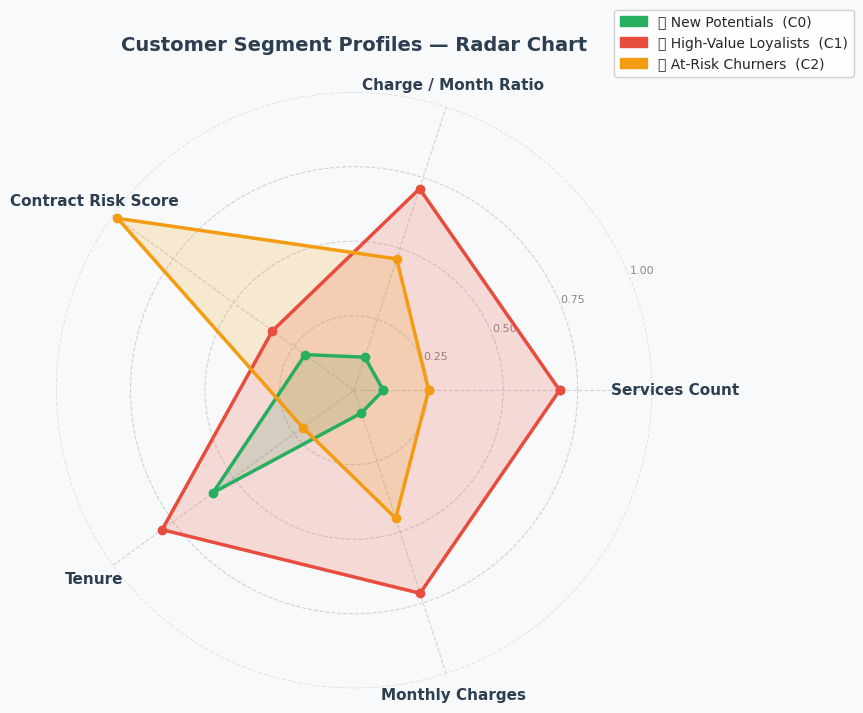

💾 Saved: 14_radar_chart.png


In [12]:
# Use scaled X_clust for radar (all values [0,1] — comparable axes)
radar_data = X_clust.copy()
radar_data['cluster_label'] = df['cluster_label'].values
radar_profile = radar_data.groupby('cluster_label')[CLUSTER_FEATURES].mean()

categories = ['Services Count', 'Charge / Month Ratio','Contract Risk Score','Tenure', 'Monthly Charges']
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]   # close the polygon

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

# Colour per cluster
colors = CLUSTER_PALETTE[:K_FINAL]
legend_handles = []

for idx, (cluster_id, row) in enumerate(radar_profile.iterrows()):
    values = row[CLUSTER_FEATURES].tolist()
    values += values[:1]
    color = colors[idx % len(colors)]
    name  = NAME_MAP.get(cluster_id, f'Cluster {cluster_id}')

    ax.plot(angles, values, 'o-', linewidth=2.5, color=color, markersize=6)
    ax.fill(angles, values, alpha=0.18, color=color)
    legend_handles.append(mpatches.Patch(color=color, label=f'{name}  (C{cluster_id})'))

# Axis labels
ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, size=11, fontweight='bold', color='#2C3E50')
ax.set_ylim(0, 1)
ax.set_yticks([0.25, 0.50, 0.75, 1.00])
ax.set_yticklabels(['0.25','0.50','0.75','1.00'], size=8, color='#888')
ax.yaxis.set_tick_params(labelsize=8)
ax.grid(color='#BDC3C7', linestyle='--', linewidth=0.8, alpha=0.7)
ax.spines['polar'].set_visible(False)

ax.set_title('Customer Segment Profiles — Radar Chart',
             size=14, fontweight='bold', pad=30, color='#2C3E50')
ax.legend(handles=legend_handles, loc='upper right',
          bbox_to_anchor=(1.35, 1.15), fontsize=10, framealpha=0.9)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/14_radar_chart.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved: 14_radar_chart.png')

## 11. Churn Rate per Cluster Bar Chart (Step 3.9)

Closes the segmentation → churn loop.  
Validates that clusters have meaningfully different churn rates — confirming business value.

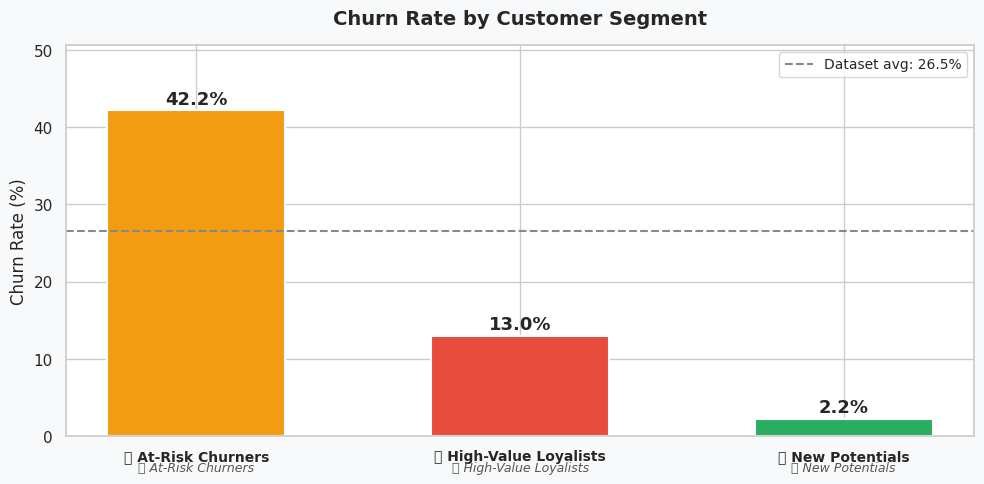

💾 Saved: 15_churn_by_cluster.png


In [13]:
churn_by_cluster = (
    df.groupby('cluster_label')
      .agg(churn_rate=('Churn_Binary', 'mean'),
           n_customers=('Churn_Binary', 'count'))
      .assign(churn_rate=lambda x: x['churn_rate']*100)
      .sort_values('churn_rate', ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(BG)

x_pos    = range(len(churn_by_cluster))
bar_cols = [colors[int(c) % len(colors)] for c in churn_by_cluster.index]
bars = ax.bar(x_pos, churn_by_cluster['churn_rate'],
              color=bar_cols, edgecolor='white', linewidth=1.5, width=0.55)

# Annotate bars
for bar, (c_id, row) in zip(bars, churn_by_cluster.iterrows()):
    name = NAME_MAP.get(c_id, f'Cluster {c_id}')
    ax.text(bar.get_x()+bar.get_width()/2,
            bar.get_height()+0.8,
            f'{row["churn_rate"]:.1f}%',
            ha='center', fontweight='bold', fontsize=13)
    ax.text(bar.get_x()+bar.get_width()/2,
            -4.5, name,
            ha='center', fontsize=9, color='#555', style='italic')

# Reference line: overall churn rate
overall_churn = df['Churn_Binary'].mean() * 100
ax.axhline(overall_churn, color='#7F8C8D', linestyle='--', linewidth=1.5,
           label=f'Dataset avg: {overall_churn:.1f}%')

x_labels = [NAME_MAP.get(c, f'C{c}') for c in churn_by_cluster.index]
ax.set_xticks(x_pos)
ax.set_xticklabels(x_labels, fontsize=10, fontweight='bold')
ax.set_ylabel('Churn Rate (%)', fontsize=12)
ax.set_title('Churn Rate by Customer Segment',
             fontsize=14, fontweight='bold', pad=15)
ax.set_ylim(0, max(churn_by_cluster['churn_rate'])*1.20)
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/15_churn_by_cluster.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved: 15_churn_by_cluster.png')

## 12. Cluster Size Distribution

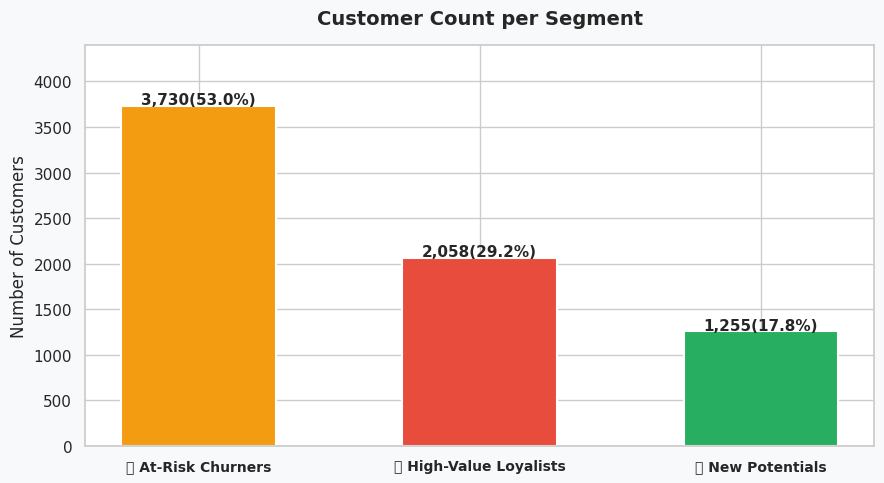

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
fig.patch.set_facecolor(BG)

size_df = df.groupby('cluster_label').size().reset_index(name='count')
size_df['name'] = size_df['cluster_label'].map(NAME_MAP)
size_df = size_df.sort_values('count', ascending=False)

bar_c = [colors[int(c) % len(colors)] for c in size_df['cluster_label']]
bars  = ax.bar(range(len(size_df)), size_df['count'],
               color=bar_c, edgecolor='white', linewidth=1.5, width=0.55)

for bar, (_, row) in zip(bars, size_df.iterrows()):
    pct = row['count']/len(df)*100
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+20,
            f'{row["count"]:,}({pct:.1f}%)',
            ha='center', fontweight='bold', fontsize=11)

ax.set_xticks(range(len(size_df)))
ax.set_xticklabels(size_df['name'], fontsize=10, fontweight='bold')
ax.set_ylabel('Number of Customers', fontsize=12)
ax.set_title('Customer Count per Segment', fontsize=14, fontweight='bold', pad=15)
ax.set_ylim(0, size_df['count'].max()*1.18)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/16_cluster_sizes.png', dpi=150, bbox_inches='tight')
plt.show()

## 13. Save Enriched Dataset + Final Summary (Step 3.9)

Append  and  to preprocessed dataset.  
This file is the **input to Phase 4** (Churn Prediction).

In [15]:
# Save enriched dataset
OUT_PATH = f'{DATA_DIR}/telco_segmented.csv'
df.to_csv(OUT_PATH, index=False)
print(f'✅ Saved: {OUT_PATH}  →  {df.shape}')
print(f'   Columns added: cluster_label, segment_name')

# ── Final summary table ──────────────────────────────────────────────────────
print('' + '═'*75)
print('PHASE 3 COMPLETE — SEGMENT SUMMARY')
print('═'*75)

summary = df.groupby(['cluster_label','segment_name']).agg(
    n_customers     = ('Churn_Binary', 'count'),
    churn_rate_pct  = ('Churn_Binary', lambda x: round(x.mean()*100,1)),
    avg_tenure      = ('tenure',        lambda x: round(x.mean()*72,1) if x.max()<=1.01 else round(x.mean(),1)),
    avg_monthly     = ('MonthlyCharges', lambda x: round(x.mean()*100,2) if x.max()<=1.01 else round(x.mean(),2)),
    avg_services    = ('services_count', 'mean'),
    avg_risk        = ('contract_risk_score', 'mean'),
).round(2).reset_index()

print(summary.to_string(index=False))
print('Figures saved:')
for fig_name in ['11_elbow_method','12_k_selection','13_dendrogram',
                  '14_radar_chart','15_churn_by_cluster','16_cluster_sizes']:
    print(f'   reports/figures/{fig_name}.png')
print('Models saved:')
print('   src/kmeans_model.pkl')
print('   src/cluster_scaler.pkl')

✅ Saved: ../data/processed/telco_segmented.csv  →  (7043, 34)
   Columns added: cluster_label, segment_name
═══════════════════════════════════════════════════════════════════════════
PHASE 3 COMPLETE — SEGMENT SUMMARY
═══════════════════════════════════════════════════════════════════════════
 cluster_label           segment_name  n_customers  churn_rate_pct  avg_tenure  avg_monthly  avg_services  avg_risk
             0       🟡 New Potentials         1255             2.2        42.1         8.02          0.69      0.41
             1 🟢 High-Value Loyalists         2058            13.0        57.3        71.63          4.83      0.68
             2     🔴 At-Risk Churners         3730            42.2        15.3        45.17          1.75      1.96
Figures saved:
   reports/figures/11_elbow_method.png
   reports/figures/12_k_selection.png
   reports/figures/13_dendrogram.png
   reports/figures/14_radar_chart.png
   reports/figures/15_churn_by_cluster.png
   reports/figures/16_cluster_s

## 14. ✅ Phase 3 Checklist

- [x] 3.1 Clustering features selected (5 business-meaningful features)
- [x] 3.2 Elbow method run for K=2–8, inertia plotted
- [x] 3.3 Silhouette score computed per K — optimal K chosen
- [x] 3.4 Final K-Means model fitted,  assigned to all customers
- [x] 3.5 Hierarchical clustering dendrogram plotted — K validated
- [x] 3.6 Cluster profiles computed (mean per feature per cluster)
- [x] 3.7 Radar/spider chart plotted — all clusters on one visual
- [x] 3.8 Clusters named in plain English (business segments)
- [x] 3.9  +  appended to dataset, saved as 
- [x] 3.10 Churn rate per cluster bar chart plotted

---

**Next notebook:**   
→ Load , use  as a feature, train Logistic Regression / Random Forest / XGBoost, compare with SHAP.